# Practical Lab — Building AI Agents with LangGraph

**Course:** Advanced Artificial Intelligence / Generative AI
**Attendees** PHD Students.
**Technology:** Python, LangChain, LangGraph, LLM APIs  
**Level:** Intermediate | **Format:** Jupyter Notebook

## 1. Lab objectives

At the end of this lab, you should be able to:

- Explain the difference between a conventional LLM chain and an agentic workflow.
- Understand the main LangGraph concepts: **State, Nodes, Edges, Conditional edges, Graph execution**.
- Build a simple conversational agent and add memory/state to it.
- Implement conditional routing and integrate tools.
- Build a multi-step research-style agent that can decide which action to perform.
- Visualize and test the resulting graph, and evaluate its behavior.

> **Tip:** Write your answers to the conceptual questions in the *"Your answer"* cells. They form part of your final report.

## PART I — Environment setup
### Exercise 1 — Install LangGraph

In [1]:
!pip install -U langgraph langchain langchain-openai langchain-community
%pip install -q -U langchain-groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 577.2/577.2 kB 17.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 86.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 62.6 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.1
    Uninstalling langchain-core-1.7.1:
      Successfully uninstalled langchain-core-1.7.1
  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.18
    Uninstalling langgraph-1.2.18:
      Successfully uninstalled langgraph-1.2.18
  Attempting uninstall: langchain
    Found existing installation: langchain 1.4.7
    Uninstalling langchain-1.4.7:
      Successfully uninstalled langchain-1.4.7
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [langchain]
ERROR: pip's dependency resolver d

In [2]:
from importlib.metadata import version

print("LangGraph:", version("langgraph"))
print("LangChain:", version("langchain"))

LangGraph: 1.2.19
LangChain: 1.4.8


### Question
What is the role of:
1. **LangChain?**
2. **LangGraph?**
3. **An LLM?**

**Your answer:**  

**Q1. What is the role of LangChain?**

- LangChain is a framework for building LLM-powered applications by connecting language models with prompts, tools, and external data.

**Q2. What is the role of LangGraph?**

- LangGraph is a framework for building stateful AI workflows using nodes, edges, and conditional routing.

**Q3. What is the role of an LLM?**

- An LLM processes natural language inputs and generates responses. In an AI agent, it can also support reasoning, classification, and tool selection.


## PART II — First LangGraph workflow
### Exercise 2 — Understanding State

In LangGraph, the **state** represents the information shared between nodes.

In [3]:
from typing import TypedDict

class AgentState(TypedDict):
    message: str
    response: str

In [4]:
def process_message(state: AgentState):
    message = state["message"]
    response = f"Agent received: {message}"
    return {"response": response}

In [5]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState)
graph_builder.add_node("process", process_message)
graph_builder.add_edge(START, "process")
graph_builder.add_edge("process", END)

graph = graph_builder.compile()

In [6]:
result = graph.invoke({
    "message": "Hello LangGraph!",
    "response": ""
})
print(result)

{'message': 'Hello LangGraph!', 'response': 'Agent received: Hello LangGraph!'}


**Expected result**
```python
{'message': 'Hello LangGraph!', 'response': 'Agent received: Hello LangGraph!'}
```

### Questions
1. What is a node?
2. What is an edge?
3. What is `START`?
4. What is `END`?
5. Why is the state passed between nodes?

**Your answer:**  

### Answers — Exercise 2

**Q1. What is a node?**

- A node is a function that performs a task within the graph and can update the shared state.

**Q2. What is an edge?**

- An edge defines the connection and execution flow between nodes.

**Q3. What is START?**

- START is the entry point of the graph.

**Q4. What is END?**

- END marks the completion of the graph execution.

**Q5. Why is the state passed between nodes?**

- The state allows nodes to share information and preserve data throughout the workflow.


## PART III — Building an LLM Agent
### Exercise 3 — Connect an LLM

**Do not hard-code the API key in the notebook.** Prefer an environment variable configured outside the notebook; otherwise prompt for it securely as below.

In [7]:

import os
from getpass import getpass
from langchain_groq import ChatGroq

os.environ["GROQ_API_KEY"] = getpass(
    "Enter your Groq API key: "
)


llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    reasoning_effort="low",
    max_tokens=2048
)


response = llm.invoke("Say hello in one short sentence.")
print(response.content)

Enter your Groq API key: ··········
Hello!


### Exercise 4 — Create an LLM node

In [8]:
class AgentState(TypedDict):
    message: str
    response: str

def chatbot(state: AgentState):
    response = llm.invoke(state["message"])
    return {"response": response.content}

graph_builder = StateGraph(AgentState)
graph_builder.add_node("chatbot", chatbot)
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

graph = graph_builder.compile()

In [9]:
result = graph.invoke({
    "message": "Explain artificial intelligence in three sentences.",
    "response": ""
})
print(result["response"])

Artificial intelligence (AI) is the field of computer science that creates systems capable of performing tasks that normally require human intelligence, such as learning, reasoning, and problem‑solving. These systems use algorithms, data, and computational power to recognize patterns, make predictions, and adapt to new information. While AI can automate routine tasks and uncover insights from vast datasets, it also raises ethical and societal questions about privacy, bias, and the future of work.


## PART IV — Multi-node AI workflow
### Exercise 5 — Build a two-stage agent

```
User question → Question analyzer → Answer generator → Final answer
```

In [10]:
class AgentState(TypedDict):
    question: str
    analysis: str
    answer: str

def analyze_question(state: AgentState):
    prompt = f"""
    Analyze the following question.

    Question:
    {state['question']}

    Identify:
    1. The topic
    2. The user's intention
    3. The information needed
    """
    response = llm.invoke(prompt)
    return {"analysis": response.content}

def generate_answer(state: AgentState):
    prompt = f"""
    Answer the user's question.

    Question:
    {state['question']}

    Analysis:
    {state['analysis']}

    Give a clear and technically correct answer.
    """
    response = llm.invoke(prompt)
    return {"answer": response.content}

In [11]:
graph_builder = StateGraph(AgentState)

graph_builder.add_node("analyzer", analyze_question)
graph_builder.add_node("answer", generate_answer)

graph_builder.add_edge(START, "analyzer")
graph_builder.add_edge("analyzer", "answer")
graph_builder.add_edge("answer", END)

graph = graph_builder.compile()

In [12]:
result = graph.invoke({
    "question": "What is reinforcement learning?",
    "analysis": "",
    "answer": ""
})
print(result["answer"])

**Reinforcement learning (RL)** is a branch of machine learning where an *agent* learns to make a sequence of decisions by interacting with an *environment*.  The agent receives a *state* description of the environment, chooses an *action*, and then the environment returns a new state and a scalar *reward*.  Over time the agent learns a *policy* (a mapping from states to actions) that maximizes the cumulative reward.

| Component | What it is | Role in RL |
|-----------|------------|------------|
| **Agent** | The learner or decision‑maker | Chooses actions, updates its policy |
| **Environment** | The world the agent interacts with | Provides states and rewards |
| **State (s)** | Current situation of the environment | Input to the agent’s policy |
| **Action (a)** | Choice the agent can make | Drives the transition to a new state |
| **Reward (r)** | Feedback signal | Guides learning (positive for good outcomes, negative for bad) |
| **Policy (π)** | Strategy for selecting actions | 

## PART V — Conditional routing

This is where LangGraph becomes particularly interesting. The agent decides which branch to follow:

```
                 ┌─── Mathematics
Question ────────┼─── Programming
                 └─── General AI
```

### Exercise 6 — Create a router

In [13]:

class AgentState(TypedDict):
    question: str
    category: str
    answer: str

def classify_question(state: AgentState):
    prompt = f"""
    Classify this question into exactly one category:

    - mathematics
    - programming
    - artificial_intelligence

    Question:
    {state['question']}

    Return only the category.
    """
    response = llm.invoke(prompt)
    return {"category": response.content.strip().lower()}

### Exercise 7 — Create specialized nodes

In [14]:

def mathematics_agent(state):
    response = llm.invoke(
        f"""
        Solve this mathematics question:

        {state['question']}
        """
    )
    return {"answer": response.content}

def programming_agent(state):
    response = llm.invoke(
        f"""
        Answer this programming question.
        Include Python code when appropriate.

        {state['question']}
        """
    )
    return {"answer": response.content}

def ai_agent(state):
    response = llm.invoke(
        f"""
        Answer this artificial intelligence question
        at university level.

        {state['question']}
        """
    )
    return {"answer": response.content}

## PART VI — Conditional edges

The routing function inspects the state and returns the **name of the next branch**.

In [15]:

def route_question(state):
    category = state["category"]

    if "mathematics" in category:
        return "math"
    if "programming" in category:
        return "programming"
    return "ai"

In [16]:

graph_builder = StateGraph(AgentState)

graph_builder.add_node("classifier", classify_question)
graph_builder.add_node("math", mathematics_agent)
graph_builder.add_node("programming", programming_agent)
graph_builder.add_node("ai", ai_agent)

graph_builder.add_edge(START, "classifier")

graph_builder.add_conditional_edges(
    "classifier",
    route_question,
    {
        "math": "math",
        "programming": "programming",
        "ai": "ai"
    }
)

graph_builder.add_edge("math", END)
graph_builder.add_edge("programming", END)
graph_builder.add_edge("ai", END)

router_graph = graph_builder.compile()

In [17]:

questions = [
    "What is the derivative of x²?",
    "How do I create a REST API with Python?",
    "What is reinforcement learning?"
]

for question in questions:
    result = router_graph.invoke({
        "question": question,
        "category": "",
        "answer": ""
    })

    print("=" * 60)
    print("QUESTION:", question)
    print("CATEGORY:", result["category"])
    print("ANSWER:", result["answer"])

QUESTION: What is the derivative of x²?
CATEGORY: mathematics
ANSWER: The derivative of \(x^2\) with respect to \(x\) is

\[
\frac{d}{dx}\,x^2 = 2x.
\]
QUESTION: How do I create a REST API with Python?
CATEGORY: programming
ANSWER: ## 1.  What is a REST API?

A **REST** (Representational State Transfer) API is a set of HTTP endpoints that expose resources (data) and let clients perform CRUD (Create, Read, Update, Delete) operations using standard HTTP verbs:

| Verb | Meaning | Typical HTTP status |
|------|---------|---------------------|
| GET  | Retrieve | 200 OK |
| POST | Create | 201 Created |
| PUT  | Replace | 200 OK / 204 No Content |
| PATCH| Update | 200 OK |
| DELETE | Remove | 204 No Content |

The API is stateless, uses JSON (or XML) as the payload format, and follows a predictable URL structure.

---

## 2.  Choose a Python web framework

| Framework | Pros | Cons | Typical use‑case |
|-----------|------|------|-----------------|
| **FastAPI** | Modern, async, automatic 

## PART VII — Agent with tools
### Exercise 8 — Create tools

The original lab uses `eval()`, which is **dangerous** (it can execute arbitrary Python). Below we first show the lab version for comparison, then a **safe** calculator built on `ast` that only allows arithmetic. We use the safe one from here on.

In [18]:
from langchain_core.tools import tool

# --- Version from the lab (UNSAFE: do not use with untrusted input) ---
@tool
def calculator_unsafe(expression: str) -> str:
    """Calculate a mathematical expression (unsafe eval version)."""
    try:
        return str(eval(expression))
    except Exception:
        return "Invalid expression"

print(calculator_unsafe.invoke("25 * 4 + 10"))   # Expected: 110

110


In [19]:
import ast
import operator as op

_ALLOWED_OPS = {
    ast.Add: op.add, ast.Sub: op.sub, ast.Mult: op.mul, ast.Div: op.truediv,
    ast.Pow: op.pow, ast.Mod: op.mod, ast.FloorDiv: op.floordiv,
    ast.USub: op.neg, ast.UAdd: op.pos,
}

def _safe_eval(node):
    if isinstance(node, ast.Expression):
        return _safe_eval(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.left), _safe_eval(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in _ALLOWED_OPS:
        return _ALLOWED_OPS[type(node.op)](_safe_eval(node.operand))
    raise ValueError("Unsupported expression")

@tool
def calculator(expression: str) -> str:
    """Calculate a mathematical expression such as '25 * 4 + 10'. Supports + - * / ** % //."""
    try:
        return str(_safe_eval(ast.parse(expression.strip(), mode="eval")))
    except Exception:
        return "Invalid expression"

print(calculator.invoke("25 * 4 + 10"))        # Expected: 110
print(calculator.invoke("__import__('os')"))   # Expected: Invalid expression

110
Invalid expression


In [20]:
from datetime import datetime

@tool
def current_datetime(_: str = "") -> str:
    """Return the current date and time. Use for any question about today's date or the current time."""
    return datetime.now().strftime("%A, %d %B %Y, %H:%M:%S")

print(current_datetime.invoke(""))

Tuesday, 03 November 2026, 17:36:14


## PART VIII — Tool-using agent

```
                 ┌─────────────┐
Question → Agent ├→ Calculator │
                 └─────────────┘
                       ↓
                    Answer
```

The agent must **decide** whether it needs the calculator. Expected behavior for *"What is 125 * 38?"*:

`Agent → recognizes math problem → calls calculator → receives result → generates answer`

We bind the tools to the LLM, so it can emit *tool calls*. A conditional edge sends the flow to the `tools` node when a tool call is present, then loops back to the agent.

In [21]:

from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition

tools = [calculator, current_datetime]

llm_with_tools = llm.bind_tools(tools)

def agent(state: MessagesState):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}

tool_builder = StateGraph(MessagesState)

tool_builder.add_node("agent", agent)
tool_builder.add_node("tools", ToolNode(tools))

tool_builder.add_edge(START, "agent")
tool_builder.add_conditional_edges("agent", tools_condition)
tool_builder.add_edge("tools", "agent")

tool_graph = tool_builder.compile()

print("Tool-using agent created successfully!")

Tool-using agent created successfully!


In [22]:
for q in ["What is 125 * 38?", "What is the capital of Morocco?"]:
    result = tool_graph.invoke({"messages": [("user", q)]})
    print("=" * 60)
    print("Q:", q)
    for m in result["messages"]:
        m.pretty_print()

Q: What is 125 * 38?
================================ Human Message =================================

What is 125 * 38?
================================== Ai Message ==================================
Tool Calls:
  calculator (fc_e3d35225-ae27-4b4f-96b1-d721d1dbf3f8)
 Call ID: fc_e3d35225-ae27-4b4f-96b1-d721d1dbf3f8
  Args:
    expression: 125 * 38
================================= Tool Message =================================
Name: calculator

4750
================================== Ai Message ==================================

125 × 38 = **4,750**
Q: What is the capital of Morocco?
================================ Human Message =================================

What is the capital of Morocco?
================================== Ai Message ==================================

The capital of Morocco is **Rabat**.


**Observe:** for the first question the trace contains an `AIMessage` with a tool call, a `ToolMessage` with the result, then the final answer. For the second question, no tool is called.

## PART IX — Memory
### Exercise 9 — Conversational state

The `add_messages` reducer **appends** new messages to the list instead of overwriting it.

In [23]:
from typing import Annotated
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list, add_messages]

def chatbot(state: ChatState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

chat_builder = StateGraph(ChatState)
chat_builder.add_node("chatbot", chatbot)
chat_builder.add_edge(START, "chatbot")
chat_builder.add_edge("chatbot", END)

**Without a checkpointer**, each `invoke` starts from scratch. **With a checkpointer** (`MemorySaver`) and a `thread_id`, the conversation persists between calls.

In [24]:
# 1) No persistence: the agent forgets
no_memory_graph = chat_builder.compile()
no_memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]})
r = no_memory_graph.invoke({"messages": [("user", "What is my name?")]})
print("WITHOUT memory:", r["messages"][-1].content)

WITHOUT memory: I don’t actually know your name—unless you tell me!


In [25]:
from langgraph.checkpoint.memory import MemorySaver

# 2) With persistence: the agent remembers within the same thread
memory_graph = chat_builder.compile(checkpointer=MemorySaver())
config = {"configurable": {"thread_id": "ahmed-1"}}

r1 = memory_graph.invoke({"messages": [("user", "My name is Ahmed.")]}, config)
print("Agent:", r1["messages"][-1].content)

r2 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, config)
print("Agent:", r2["messages"][-1].content)

# A different thread has its own, separate memory
other = {"configurable": {"thread_id": "someone-else"}}
r3 = memory_graph.invoke({"messages": [("user", "What is my name?")]}, other)
print("Other thread:", r3["messages"][-1].content)

Agent: Hello Ahmed! How can I help you today?
Agent: Your name is Ahmed.
Other thread: I don’t actually know your name—unless you tell me!


## Visualizing and testing graphs

`get_graph()` returns a drawable representation. If PNG rendering is unavailable (it may need network access), print the Mermaid source and paste it into <https://mermaid.live>.

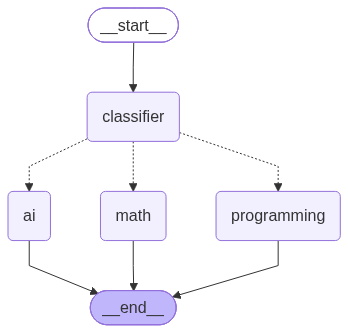

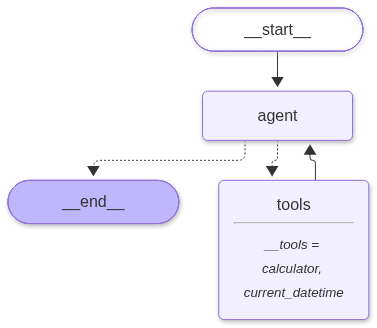

In [26]:
from IPython.display import Image, display

def show_graph(g):
    try:
        display(Image(g.get_graph().draw_mermaid_png()))
    except Exception as e:
        print("PNG rendering unavailable:", e)
        print(g.get_graph().draw_mermaid())

show_graph(router_graph)
show_graph(tool_graph)

## Evaluating the behavior of an agentic workflow

A minimal evaluation harness: define test cases with expected categories, run them, and compute accuracy. You can extend this with tool-call checks, latency, and cost.

In [27]:
import time

test_cases = [
    ("What is the derivative of x²?", "mathematics"),
    ("Solve 2x + 3 = 11", "mathematics"),
    ("How do I reverse a list in Python?", "programming"),
    ("Write a function to check for palindromes.", "programming"),
    ("What is a convolutional neural network?", "artificial_intelligence"),
    ("Explain overfitting.", "artificial_intelligence"),
]

correct, rows = 0, []
for q, expected in test_cases:
    t0 = time.time()
    out = router_graph.invoke({"question": q, "category": "", "answer": ""})
    got = out["category"]
    ok = expected in got
    correct += ok
    rows.append((q, expected, got, ok, round(time.time() - t0, 2)))

import pandas as pd
df = pd.DataFrame(rows, columns=["question", "expected", "got", "correct", "seconds"])
display(df)
print(f"Routing accuracy: {correct}/{len(test_cases)} = {correct/len(test_cases):.0%}")

,question,expected,got,correct,seconds
0,What is the derivative of x²?,mathematics,mathematics,True,0.82
1,Solve 2x + 3 = 11,mathematics,mathematics,True,2.25
2,How do I reverse a list in Python?,programming,programming,True,1.78
3,Write a function to check for palindromes.,programming,programming,True,2.02
4,What is a convolutional neural network?,artificial_intelligence,artificial_intelligence,True,2.91
5,Explain overfitting.,artificial_intelligence,artificial_intelligence,True,2.24


Routing accuracy: 6/6 = 100%


**Discussion:** Where did the router fail (if anywhere)? What would make the routing more robust (structured output, few-shot examples, enum validation)?

**Your answer:**

### Answers — Routing Evaluation

**Q1. Where did the router fail (if anywhere)?**

- The router achieved **100% accuracy (6/6)** on the evaluation dataset.
- All mathematics, programming, and artificial intelligence questions were correctly classified.
- No routing errors were observed in this experiment.

**Q2. What would make the routing more robust?**

- **Structured output:** Force the classifier to return a predefined category.
- **Few-shot prompting:** Provide examples of correctly classified questions.
- **Enum validation:** Reject unexpected categories.
- **Error handling:** Provide a fallback when classification fails.
- **More testing:** Evaluate the router using ambiguous and complex questions.

**Conclusion**

- The conditional routing system performed successfully on all six test questions. However, a larger and more diverse evaluation dataset is necessary to assess its reliability.

## PART X — Capstone project: Intelligent University Assistant

### Requirements covered below
| # | Requirement | Implementation |
|---|---|---|
| 1 | Question classifier | `classify` node → COURSES / PROGRAMMING / MATHEMATICS / ADMINISTRATION / GENERAL |
| 2 | Specialized agents | one node per category, built with `make_agent` |
| 3 | Memory | `MemorySaver` checkpointer + `thread_id` |
| 4 | Tools | `calculator`, `current_datetime` (+ optional extras) |
| 5 | Conditional routing | `route_after_classifier`, `route_after_agent`, `route_after_tools` |
| 6 | Error handling | empty input, unknown category, invalid tool calls, API errors |

### Architecture
```
User question → Classifier ─┬→ Courses Agent ──────┐
                            ├→ Programming Agent ──┤
                            ├→ Mathematics Agent ──┼→ Tool decision ─→ Tools (Calculator / Date-time / ...)
                            ├→ Administration Agent┤        │                │
                            ├→ General Agent ──────┘        ▼                │
                            └→ Fallback (empty/error)   Final response ◄─────┘
```
Each agent decides whether to call a tool; after the tool runs, control returns to the **same** agent, which writes the final response.

In [28]:

from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages
from langchain_core.messages import SystemMessage, AIMessage, HumanMessage

CATEGORIES  = ["COURSES", "PROGRAMMING", "MATHEMATICS", "ADMINISTRATION", "GENERAL"]

class AssistantState(TypedDict):
    messages: Annotated[list, add_messages]
    category: str

print("Assistant State created successfully!")
print("Categories:", CATEGORIES)


Assistant State created successfully!
Categories: ['COURSES', 'PROGRAMMING', 'MATHEMATICS', 'ADMINISTRATION', 'GENERAL']


### 1. Classifier (with error handling)

In [29]:
def classify(state: AssistantState):
    last = state["messages"][-1]
    text = (last.content if hasattr(last, "content") else str(last)).strip()

    # Error handling: empty question
    if not text:
        return {"category": "EMPTY"}

    prompt = f"""
    Classify the student's question into exactly one category:
    COURSES (course content, syllabus, schedules, exams, grading),
    PROGRAMMING, MATHEMATICS,
    ADMINISTRATION (enrollment, fees, certificates, procedures, deadlines),
    GENERAL (anything else).

    Question: {text}

    Return only the category name.
    """
    try:
        raw = llm.invoke(prompt).content.strip().upper()
    except Exception as e:                      # Error handling: API errors
        print("Classifier API error:", e)
        return {"category": "ERROR"}

    # Error handling: unknown/unexpected label -> GENERAL
    category = next((c for c in CATEGORIES if c in raw), "GENERAL")
    return {"category": category}

### 2. Specialized agents (factory) + fallback node

In [30]:
SYSTEM_PROMPTS = {
    "COURSES": "You are a university courses advisor. Explain course content, prerequisites, "
               "schedules and study strategies. If you lack institution-specific data, say so honestly.",
    "PROGRAMMING": "You are a programming tutor. Give clear explanations and correct Python code when appropriate.",
    "MATHEMATICS": "You are a mathematics tutor. Show steps. ALWAYS use the calculator tool for arithmetic.",
    "ADMINISTRATION": "You are a university administration assistant (enrollment, fees, certificates, procedures). "
                      "Never invent official rules or deadlines; recommend contacting the administration office when unsure.",
    "GENERAL": "You are a helpful university assistant. Use the date/time tool for questions about the current date or time.",
}

def make_agent(category: str):
    system = SystemMessage(content=SYSTEM_PROMPTS[category])

    def node(state: AssistantState):
        try:
            response = llm_with_tools.invoke([system] + state["messages"])
            return {"messages": [response]}
        except Exception as e:                  # Error handling: API errors
            return {"messages": [AIMessage(
                content=f"Sorry, I ran into a technical problem while answering ({type(e).__name__}). Please try again."
            )]}
    return node

def fallback(state: AssistantState):
    if state["category"] == "EMPTY":
        msg = "Your question seems to be empty. Please type a question and I'll help."
    else:
        msg = "Sorry, I couldn't process your question right now. Please try again in a moment."
    return {"messages": [AIMessage(content=msg)]}

### 3. Routing functions and graph assembly

`ToolNode(..., handle_tool_errors=True)` converts invalid tool calls / tool exceptions into error messages the agent can recover from, instead of crashing the graph.

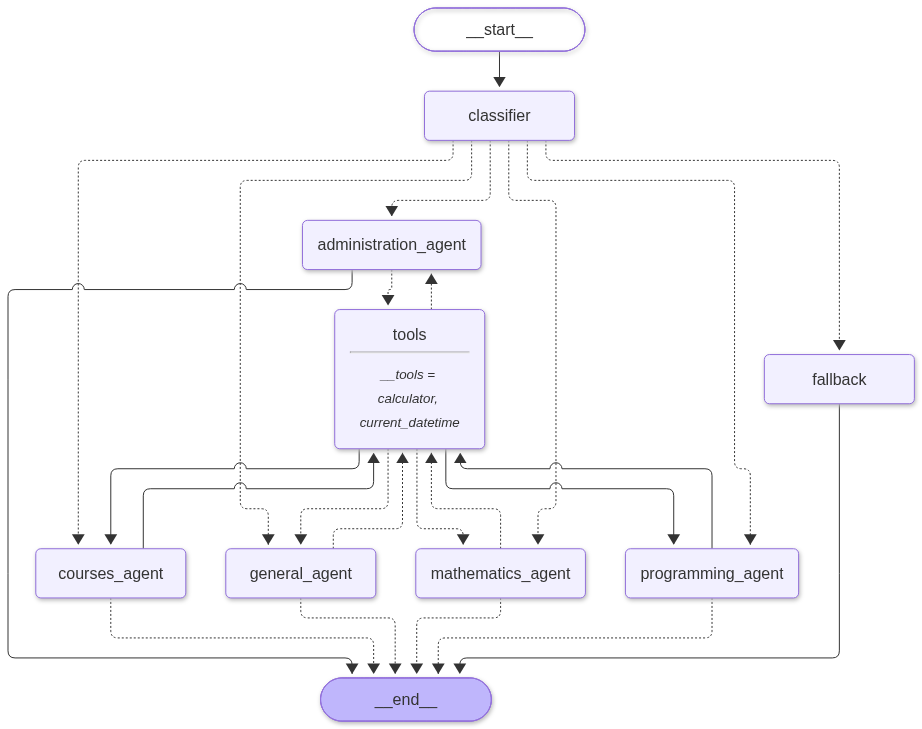

In [31]:
NODE_NAMES = {c: f"{c.lower()}_agent" for c in CATEGORIES}

def route_after_classifier(state: AssistantState):
    return NODE_NAMES.get(state["category"], "fallback")

def route_after_agent(state: AssistantState):
    last = state["messages"][-1]
    return "tools" if getattr(last, "tool_calls", None) else END

def route_after_tools(state: AssistantState):
    # return to the agent that requested the tool
    return NODE_NAMES.get(state["category"], "general_agent")

builder = StateGraph(AssistantState)
builder.add_node("classifier", classify)
builder.add_node("fallback", fallback)
builder.add_node("tools", ToolNode(tools, handle_tool_errors=True))
for c in CATEGORIES:
    builder.add_node(NODE_NAMES[c], make_agent(c))

builder.add_edge(START, "classifier")
builder.add_conditional_edges(
    "classifier", route_after_classifier,
    {**{n: n for n in NODE_NAMES.values()}, "fallback": "fallback"},
)
for c in CATEGORIES:
    builder.add_conditional_edges(NODE_NAMES[c], route_after_agent, {"tools": "tools", END: END})
builder.add_conditional_edges("tools", route_after_tools, {n: n for n in NODE_NAMES.values()})
builder.add_edge("fallback", END)

assistant = builder.compile(checkpointer=MemorySaver())
show_graph(assistant)

### 4. Demonstration — at least 5 different user queries
Includes: all categories, both tools, memory, and error cases (empty input).

In [32]:
def ask(question: str, thread_id: str = "demo"):
    config = {"configurable": {"thread_id": thread_id}}
    result = assistant.invoke({"messages": [HumanMessage(content=question)]}, config)
    print("=" * 70)
    print("USER    :", question)
    print("CATEGORY:", result["category"])
    print("ASSISTANT:", result["messages"][-1].content)
    return result

demo_queries = [
    "What topics are usually covered in a machine learning course?",     # COURSES
    "Write a Python function that computes the factorial of n.",         # PROGRAMMING
    "What is 125 * 38 + 17?",                                            # MATHEMATICS (calculator)
    "How do I request an enrollment certificate?",                       # ADMINISTRATION
    "What is today's date?",                                             # GENERAL (date/time tool)
    "   ",                                                               # Error: empty question
]
for q in demo_queries:
    ask(q)

USER    : What topics are usually covered in a machine learning course?
CATEGORY: COURSES
ASSISTANT: A typical undergraduate or graduate‑level machine learning (ML) course covers a blend of theory, algorithms, and practical implementation. Below is a high‑level outline of the main topics you’ll usually encounter, along with brief explanations and some common prerequisites.

| # | Topic | Key Concepts | Typical Prerequisites |
|---|-------|--------------|-----------------------|
| 1 | **Introduction & Problem Formulation** | • Supervised vs. unsupervised learning<br>• Regression, classification, clustering, dimensionality reduction<br>• Evaluation metrics (accuracy, precision, recall, ROC, etc.) | • Basic probability & statistics<br>• Linear algebra (vectors, matrices) |
| 2 | **Linear Models** | • Linear regression (OLS, regularization: Ridge, Lasso)<br>• Logistic regression<br>• Gradient descent & variants | • Calculus (derivatives), optimization basics |
| 3 | **Probabilistic Models*

In [33]:
# Memory test: same thread_id
ask("My name is Ahmed.", thread_id="memory-test")
ask("What is my name?", thread_id="memory-test");

USER    : My name is Ahmed.
CATEGORY: GENERAL
ASSISTANT: Hello Ahmed! How can I help you today?
USER    : What is my name?
CATEGORY: GENERAL
ASSISTANT: Your name is Ahmed.


In [34]:
# Inspect the full message trace (including tool calls) of one run
r = assistant.invoke(
    {"messages": [HumanMessage(content="Compute (15 + 27) * 3 using the calculator.")]},
    {"configurable": {"thread_id": "trace"}},
)
for m in r["messages"]:
    m.pretty_print()

================================ Human Message =================================

Compute (15 + 27) * 3 using the calculator.
================================== Ai Message ==================================
Tool Calls:
  calculator (fc_2cd0f83d-5df5-4978-9e4b-4635f7fb11b9)
 Call ID: fc_2cd0f83d-5df5-4978-9e4b-4635f7fb11b9
  Args:
    expression: (15 + 27) * 3
================================= Tool Message =================================
Name: calculator

126
================================== Ai Message ==================================

**Step 1: Compute the sum inside the parentheses**

\(15 + 27 = 42\)

**Step 2: Multiply the result by 3**

\(42 \times 3 = 126\)

\[
(15 + 27) \times 3 = 126
\]


In [35]:

from langchain_core.messages import HumanMessage, ToolMessage

result = assistant.invoke(
    {
        "messages": [
            HumanMessage(
                content="Use the current_datetime tool to tell me today's date and time."
            )
        ]
    },
    {"configurable": {"thread_id": "date-tool-final-test"}}
)

tool_calls = [
    call["name"]
    for message in result["messages"]
    for call in getattr(message, "tool_calls", [])
]

print("Category:", result["category"])
print("Tools called:", tool_calls)
print("Final answer:", result["messages"][-1].content)

assert "current_datetime" in tool_calls, (
    "The date/time tool was not called."
)

print("Date/Time Tool: PASS")

Category: PROGRAMMING
Tools called: ['current_datetime']
Final answer: Today is **Tuesday, 03 November 2026**, and the current time is **17:41:33**.
Date/Time Tool: PASS


### 5. Optional extensions
Add one or more of: Wikipedia, web search, a database (e.g. SQLite with course data), a PDF reader, or weather. Implement each as a `@tool`, append it to the `tools` list **before** calling `llm.bind_tools(...)`, and rebuild the graph.

```python
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
wiki = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
```

In [36]:
# Create SQLite Database
import sqlite3

DB_PATH = "university_courses_demo.db"

courses = [
    (
        "ML101",
        "Machine Learning",
        "Supervised learning, unsupervised learning, model evaluation.",
        6,
        "Python, Statistics, Linear Algebra"
    ),
    (
        "DL201",
        "Deep Learning",
        "Neural networks, CNNs, RNNs, Transformers.",
        6,
        "Machine Learning, Python"
    ),
    (
        "PY101",
        "Python Programming",
        "Python syntax, functions, OOP, data structures.",
        4,
        "None"
    ),
    (
        "DB101",
        "Database Systems",
        "SQL, relational databases, normalization, transactions.",
        5,
        "Basic Programming"
    ),
    (
        "MA101",
        "Linear Algebra",
        "Vectors, matrices, eigenvalues, linear transformations.",
        5,
        "Basic Mathematics"
    )
]

conn = sqlite3.connect(DB_PATH)

conn.execute("""
CREATE TABLE IF NOT EXISTS courses (
    code TEXT PRIMARY KEY,
    title TEXT NOT NULL,
    description TEXT,
    credits INTEGER,
    prerequisites TEXT
)
""")

conn.executemany("""
INSERT OR REPLACE INTO courses
(code, title, description, credits, prerequisites)
VALUES (?, ?, ?, ?, ?)
""", courses)

conn.commit()
conn.close()

print("SQLite Database: CREATED")
print("Number of courses:", len(courses))

SQLite Database: CREATED
Number of courses: 5


In [37]:
# Create SQLite Tool
from langchain_core.tools import tool
import sqlite3

@tool
def search_courses(course_name: str) -> str:
    """Search the demo university database for courses, credits and prerequisites."""

    conn = sqlite3.connect(DB_PATH)

    try:
        cursor = conn.execute("""
            SELECT code, title, description, credits, prerequisites
            FROM courses
            WHERE LOWER(title) LIKE LOWER(?)
               OR LOWER(code) LIKE LOWER(?)
        """, (
            f"%{course_name}%",
            f"%{course_name}%"
        ))

        rows = cursor.fetchall()

    finally:
        conn.close()

    if not rows:
        return "No matching course found in the demo database."

    results = []

    for code, title, description, credits, prerequisites in rows:
        results.append(
            f"Course: {title}\n"
            f"Code: {code}\n"
            f"Description: {description}\n"
            f"Credits: {credits}\n"
            f"Prerequisites: {prerequisites}"
        )

    return "\n\n".join(results)


print(search_courses.invoke("Machine Learning"))

Course: Machine Learning
Code: ML101
Description: Supervised learning, unsupervised learning, model evaluation.
Credits: 6
Prerequisites: Python, Statistics, Linear Algebra


In [38]:
# Register the New Tool
tools = [
    calculator,
    current_datetime,
    search_courses
]

# Encourage the Courses Agent to use the database
SYSTEM_PROMPTS["COURSES"] = (
    "You are a university courses advisor. "
    "For questions about course names, descriptions, credits "
    "or prerequisites, use the search_courses tool. "
    "The database contains fictional demonstration data, "
    "not official university records. "
    "Do not invent courses or prerequisites."
)

llm_with_tools = llm.bind_tools(tools)

print("Registered Tools:")

for t in tools:
    print("-", t.name)


Registered Tools:
- calculator
- current_datetime
- search_courses


In [39]:
# Rebuild the LangGraph Assistant
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

builder = StateGraph(AssistantState)

builder.add_node("classifier", classify)
builder.add_node("fallback", fallback)
builder.add_node("tools", ToolNode(tools))

for category in CATEGORIES:
    builder.add_node(
        category.lower(),
        make_agent(category)
    )

def choose_agent(state):
    if state["category"] in CATEGORIES:
        return state["category"].lower()
    return "fallback"

def after_agent(state):
    last = state["messages"][-1]

    if getattr(last, "tool_calls", None):
        return "tools"

    return END

def resume_agent(state):
    return state["category"].lower()

builder.add_edge(START, "classifier")

builder.add_conditional_edges(
    "classifier",
    choose_agent,
    {
        **{c.lower(): c.lower() for c in CATEGORIES},
        "fallback": "fallback"
    }
)

for category in CATEGORIES:
    builder.add_conditional_edges(
        category.lower(),
        after_agent,
        {
            "tools": "tools",
            END: END
        }
    )

builder.add_conditional_edges(
    "tools",
    resume_agent,
    {c.lower(): c.lower() for c in CATEGORIES}
)

builder.add_edge("fallback", END)

assistant = builder.compile(
    checkpointer=MemorySaver()
)

print("University Assistant with SQLite: READY")

University Assistant with SQLite: READY


In [40]:
# Test SQLite Tool Calling

from langchain_core.messages import HumanMessage, ToolMessage

result = assistant.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "According to the demo course database, "
                    "what are the prerequisites for Machine Learning? "
                    "Use search_courses to look it up."
                )
            )
        ]
    },
    {
        "configurable": {
            "thread_id": "sqlite-test"
        }
    }
)

tool_calls = [
    call["name"]
    for msg in result["messages"]
    for call in getattr(msg, "tool_calls", [])
]

print("CATEGORY:", result["category"])
print("TOOLS CALLED:", tool_calls)
print("ANSWER:", result["messages"][-1].content)

assert "search_courses" in tool_calls, (
    "SQLite tool was not called."
)

print("SQLite Integration: PASS")

CATEGORY: COURSES
TOOLS CALLED: ['search_courses']
ANSWER: **Prerequisites for Machine Learning (ML101):**

- Python  
- Statistics  
- Linear Algebra
SQLite Integration: PASS


## Deliverables checklist

- [ ] `langgraph_lab.ipynb` (this notebook, executed, with outputs)
- [ ] `README.md` (setup, how to run, design choices)
- [ ] Source code
- [ ] Architecture diagram (export from `show_graph(assistant)` or Mermaid)
- [ ] Screenshots showing execution
- [ ] Short report answering the conceptual questions